# MLP vs GRU: training and generated samples

Compares the two autoregressive models of Phase 1 against the real and shuffled control sets.

This notebook only reads results; it does not train or sample. Produce them first with:


In [2]:
import math
import re
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

cwd = Path.cwd()
ROOT = cwd if (cwd / "results").is_dir() else cwd.parent
if not (ROOT / "results").is_dir():
    raise FileNotFoundError("Run this notebook from the project root or its notebooks/ directory")

COMPARISON = ROOT / "results/structure_comparison_week2"
structures = pd.read_csv(COMPARISON / "structures.csv")
summary = pd.read_csv(COMPARISON / "summary.csv").set_index("set")

# The order every table and figure below uses: worst to best, with the two controls at the ends.
SETS = ["shuffled", "mlp", "gru", "real"]
LABELS = {"shuffled": "Shuffled", "mlp": "MLP", "gru": "GRU", "real": "Real"}
COLOURS = {"shuffled": "#999999", "mlp": "#d95f02", "gru": "#1b9e77", "real": "#7570b3"}

print(f"{len(structures)} structures across {structures['set'].nunique()} sets")
structures.groupby("set").size()

1024 structures across 4 sets


set
gru         256
mlp         256
real        256
shuffled    256
dtype: int64

## How the models trained

The epoch logs of every run, so the architectures can be compared on next-token loss before
looking at what they generate. Cross-entropy is in nats; its exponential is the perplexity, the
effective number of residues the model is still choosing between at each position.

In [3]:
RUNS = {
    "MLP (h=256)": "train_mlp.log",
    "GRU 1x128": "train_gru_h128_l1.log",
    "GRU 2x256": "train_gru_h256_l2.log",
    "GRU 3x256": "train_gru_h256_l3.log",
}
EPOCH = re.compile(
    r"epoch (\d+)/\d+ train_loss=([\d.]+) train_acc=([\d.]+)% "
    r"val_loss=([\d.]+) val_acc=([\d.]+)%"
)

histories = {}
for name, filename in RUNS.items():
    path = ROOT / "results" / filename
    if not path.is_file():
        print(f"missing {path}")
        continue
    rows = [
        {
            "epoch": int(m[1]),
            "train_loss": float(m[2]),
            "train_acc": float(m[3]) / 100,
            "val_loss": float(m[4]),
            "val_acc": float(m[5]) / 100,
        }
        for m in (EPOCH.match(line) for line in path.read_text().splitlines())
        if m
    ]
    histories[name] = pd.DataFrame(rows).set_index("epoch")

list(histories)

['MLP (h=256)', 'GRU 1x128', 'GRU 2x256', 'GRU 3x256']

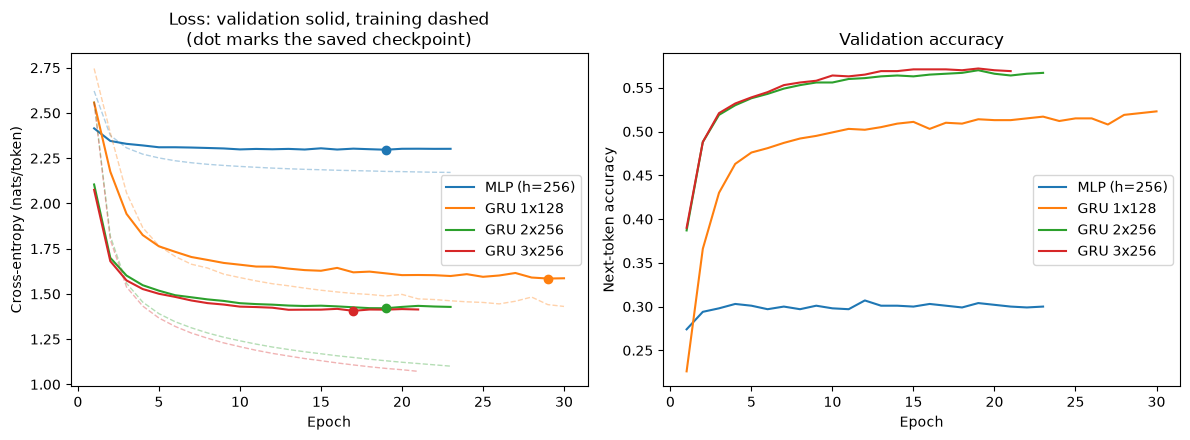

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name, history in histories.items():
    line, = axes[0].plot(history.index, history["val_loss"], label=name)
    axes[0].plot(
        history.index, history["train_loss"],
        color=line.get_color(), alpha=0.35, linestyle="--", linewidth=1,
    )
    best = history["val_loss"].idxmin()
    axes[0].scatter([best], [history.loc[best, "val_loss"]], color=line.get_color(), zorder=3)
    axes[1].plot(history.index, history["val_acc"], label=name)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy (nats/token)")
axes[0].set_title("Loss: validation solid, training dashed\n(dot marks the saved checkpoint)")
axes[0].legend()

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Next-token accuracy")
axes[1].set_title("Validation accuracy")
axes[1].legend()

fig.tight_layout()

### Capacity against fit

Parameter counts come from the model classes themselves, so the table cannot drift from the code.
The point of the ablation is where added capacity stops paying for itself.

In [5]:
from protgen.models import GRU, MLP

ARCHITECTURES = {
    "MLP (h=256)": MLP(vocab_size=23, hidden_dim=256),
    "GRU 1x128": GRU(vocab_size=23, hidden_dim=128, num_layers=1),
    "GRU 2x256": GRU(vocab_size=23, hidden_dim=256, num_layers=2),
    "GRU 3x256": GRU(vocab_size=23, hidden_dim=256, num_layers=3),
}

ablation = pd.DataFrame(
    [
        {
            "parameters": sum(p.numel() for p in model.parameters()),
            "best_val_loss": histories[name]["val_loss"].min(),
            "perplexity": math.exp(histories[name]["val_loss"].min()),
            "best_val_acc": histories[name].loc[histories[name]["val_loss"].idxmin(), "val_acc"],
            "best_epoch": int(histories[name]["val_loss"].idxmin()),
            "epochs_run": int(histories[name].index.max()),
        }
        for name, model in ARCHITECTURES.items()
        if name in histories
    ],
    index=[name for name in ARCHITECTURES if name in histories],
).rename_axis("model")
ablation.round(3)

,parameters,best_val_loss,perplexity,best_val_acc,best_epoch,epochs_run
model,,,,,,
MLP (h=256),163063,2.297,9.943,0.304,19,23
GRU 1x128,65911,1.585,4.879,0.521,29,30
GRU 2x256,624119,1.421,4.140,0.570,19,23
GRU 3x256,1018871,1.406,4.082,0.571,17,21


## What the models generate

`nearest_identity` is the identity to the closest training sequence. On its own it says little:
the shuffled control is novel too. It is read against both controls, where the real set marks the
identity that genuine held-out proteins reach.

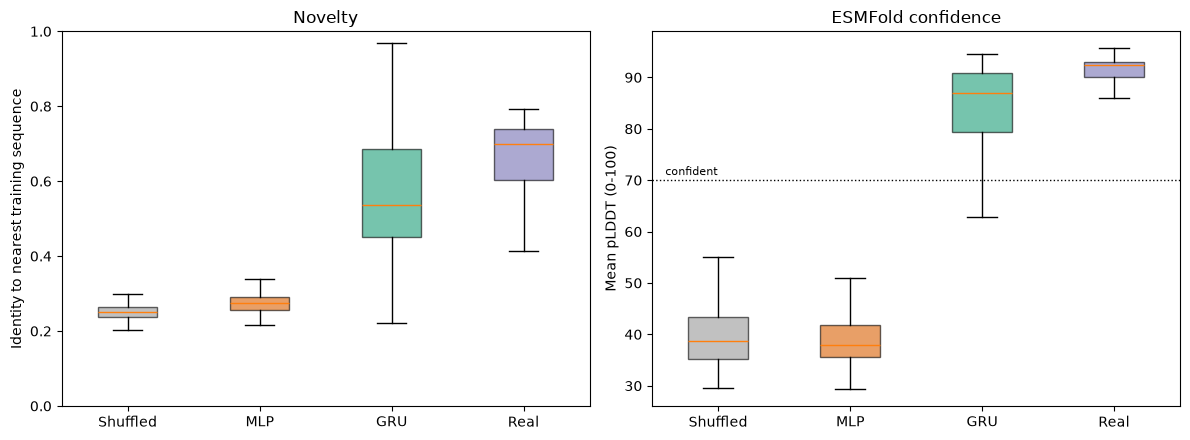

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

identity = [structures.loc[structures["set"] == s, "nearest_identity"].dropna() for s in SETS]
box = axes[0].boxplot(identity, showfliers=False, patch_artist=True)
for patch, name in zip(box["boxes"], SETS):
    patch.set_facecolor(COLOURS[name])
    patch.set_alpha(0.6)
axes[0].set_xticks(range(1, len(SETS) + 1), [LABELS[s] for s in SETS])
axes[0].set_ylabel("Identity to nearest training sequence")
axes[0].set_ylim(0, 1)
axes[0].set_title("Novelty")

plddt = [structures.loc[structures["set"] == s, "mean_plddt"].dropna() for s in SETS]
box = axes[1].boxplot(plddt, showfliers=False, patch_artist=True)
for patch, name in zip(box["boxes"], SETS):
    patch.set_facecolor(COLOURS[name])
    patch.set_alpha(0.6)
axes[1].axhline(70, color="black", linestyle=":", linewidth=1)
axes[1].text(0.6, 71, "confident", fontsize=8)
axes[1].set_xticks(range(1, len(SETS) + 1), [LABELS[s] for s in SETS])
axes[1].set_ylabel("Mean pLDDT (0-100)")
axes[1].set_title("ESMFold confidence")

fig.tight_layout()

### The trade-off

High confidence is easy to reach by copying, so pLDDT alone does not say a model is good. Plotting
it against identity separates the two: a model in the upper left folds confidently *and* writes
sequences it was not shown.

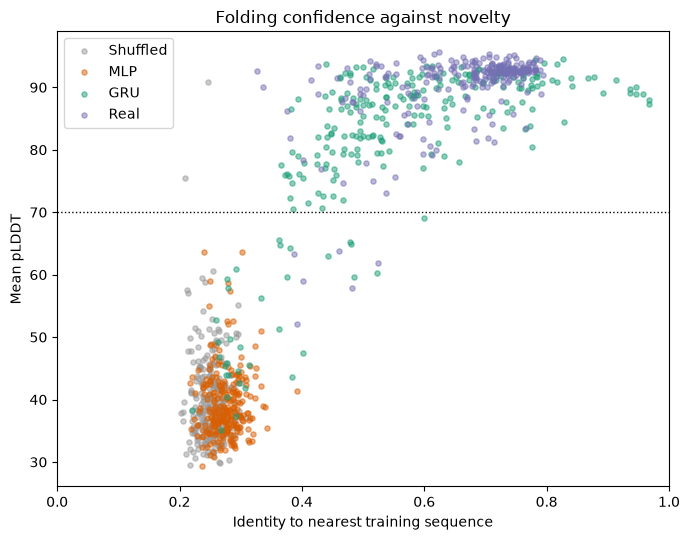

In [7]:
fig, ax = plt.subplots(figsize=(7, 5.5))

for name in SETS:
    subset = structures[structures["set"] == name]
    ax.scatter(
        subset["nearest_identity"], subset["mean_plddt"],
        s=14, alpha=0.5, color=COLOURS[name], label=LABELS[name],
    )

ax.axhline(70, color="black", linestyle=":", linewidth=1)
ax.set_xlabel("Identity to nearest training sequence")
ax.set_ylabel("Mean pLDDT")
ax.set_xlim(0, 1)
ax.set_title("Folding confidence against novelty")
ax.legend()
fig.tight_layout()

## Structure

The sequence metrics stop at "does ESMFold believe it". These ask whether the predicted structure
is the *right* one: `frac_same_fold_tm_gt0.5` is the share of samples whose closest real structure
scores above the usual same-fold threshold, and the secondary-structure fractions say which
elements the model reproduces.

In [8]:
REPORTED = [
    "mean_plddt",
    "frac_plddt_gt70",
    "frac_same_fold_tm_gt0.5",
    "median_best_tm",
    "mean_pairwise_tm",
    "frac_helix",
    "frac_strand",
    "median_rg_norm",
]
summary.loc[SETS, REPORTED].rename(index=LABELS).round(3)

,mean_plddt,frac_plddt_gt70,frac_same_fold_tm_gt0.5,median_best_tm,mean_pairwise_tm,frac_helix,frac_strand,median_rg_norm
set,,,,,,,,
Shuffled,40.111,0.008,0.000,0.258,0.169,0.362,0.062,1.197
MLP,39.174,0.000,0.008,0.263,0.187,0.351,0.078,1.160
GRU,81.958,0.867,0.930,0.897,0.390,0.354,0.237,1.064
Real,90.184,0.977,1.000,0.944,0.447,0.351,0.254,0.988


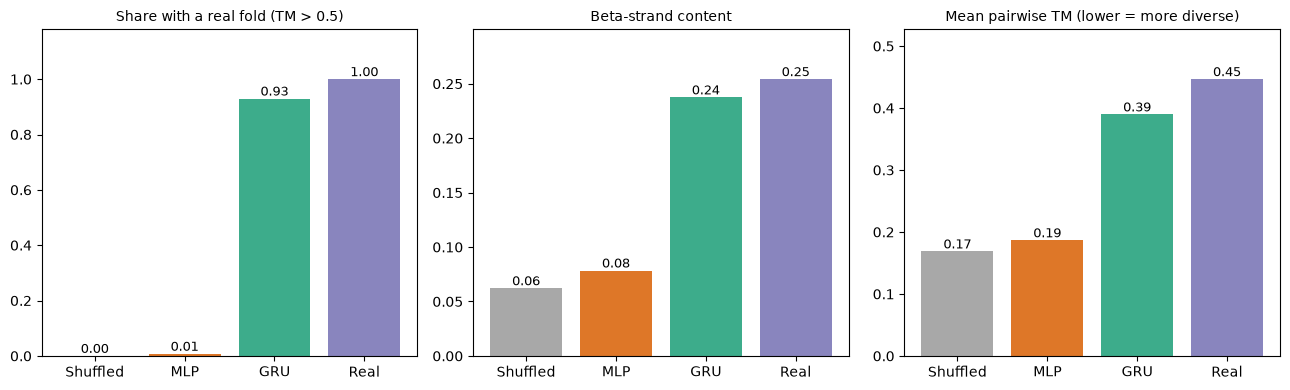

In [9]:
PANELS = [
    ("frac_same_fold_tm_gt0.5", "Share with a real fold (TM > 0.5)"),
    ("frac_strand", "Beta-strand content"),
    ("mean_pairwise_tm", "Mean pairwise TM (lower = more diverse)"),
]

fig, axes = plt.subplots(1, len(PANELS), figsize=(13, 4))
for ax, (column, title) in zip(axes, PANELS):
    values = summary.loc[SETS, column]
    ax.bar(
        range(len(SETS)), values,
        color=[COLOURS[s] for s in SETS], alpha=0.85,
    )
    ax.set_xticks(range(len(SETS)), [LABELS[s] for s in SETS])
    ax.set_title(title, fontsize=10)
    for index, value in enumerate(values):
        ax.text(index, value, f"{value:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, max(values) * 1.18)

fig.tight_layout()

### Confidence along the chain

Sampling draws a target length from the training set and stops there rather than letting the model
emit `<EOS>`, so sequences can be cut mid-structure. If that happens, the drop shows up at the
C-terminus and not in the core. `generate.py --free-length` is the check.

In [ ]:
POSITIONS = ["plddt_first15", "plddt_core", "plddt_last15"]
LABELS_POS = ["First 15", "Core", "Last 15"]

fig, ax = plt.subplots(figsize=(7, 4.5))
for name in SETS:
    subset = structures[structures["set"] == name]
    ax.plot(
        LABELS_POS, [subset[column].median() for column in POSITIONS],
        marker="o", color=COLOURS[name], label=LABELS[name],
    )

ax.set_ylabel("Median pLDDT")
ax.set_title("Where along the chain the model is confident")
ax.legend()
fig.tight_layout()

## The report table

One row per model, combining how it fit the data with what it generated.

In [ ]:
report = pd.DataFrame(
    {
        "parameters": [
            None,
            ablation.loc["MLP (h=256)", "parameters"],
            ablation.loc["GRU 2x256", "parameters"],
            None,
        ],
        "val_loss": [
            None,
            ablation.loc["MLP (h=256)", "best_val_loss"],
            ablation.loc["GRU 2x256", "best_val_loss"],
            None,
        ],
        "val_acc": [
            None,
            ablation.loc["MLP (h=256)", "best_val_acc"],
            ablation.loc["GRU 2x256", "best_val_acc"],
            None,
        ],
        "median_identity": [
            structures.loc[structures["set"] == s, "nearest_identity"].median() for s in SETS
        ],
        "mean_plddt": summary.loc[SETS, "mean_plddt"].to_numpy(),
        "frac_plddt_gt70": summary.loc[SETS, "frac_plddt_gt70"].to_numpy(),
        "frac_same_fold": summary.loc[SETS, "frac_same_fold_tm_gt0.5"].to_numpy(),
        "frac_strand": summary.loc[SETS, "frac_strand"].to_numpy(),
    },
    index=[LABELS[s] for s in SETS],
).rename_axis("set")
report.round(3)

In [ ]:
def as_markdown(frame):
    """Markdown rows to paste into the report, without pulling in tabulate."""
    header = [frame.index.name or ""] + list(frame.columns)
    rows = [
        [str(index)] + ["" if pd.isna(value) else f"{value:g}" for value in row]
        for index, row in frame.iterrows()
    ]
    widths = [max(len(row[i]) for row in [header, *rows]) for i in range(len(header))]
    lines = [
        "| " + " | ".join(cell.ljust(width) for cell, width in zip(header, widths)) + " |",
        "|" + "|".join("-" * (width + 2) for width in widths) + "|",
    ]
    lines += [
        "| " + " | ".join(cell.ljust(width) for cell, width in zip(row, widths)) + " |"
        for row in rows
    ]
    return "\n".join(lines)


print(as_markdown(report.round(3)))